# Training MLP — Hybrid (4 lớp) và triển khai Edge AI

Notebook này chỉ huấn luyện mô hình trên bộ đặc trưng **Hybrid** đã tạo ở giai đoạn 1.

**Đầu ra:** bảng Accuracy/Macro-F1 theo seed và mean ± std; Learning Curves 100 epoch; Confusion Matrix tổng hợp 10 seed; Ablation Study theo nhóm đặc trưng; mô hình `.h5` và TFLite full-integer INT8 cho STM32Cube.AI.

**Giao thức:** Stratified Group K-Fold với nhóm `file_id`, `k=4`, seed 42–51. Tất cả cửa sổ của một file luôn nằm trong cùng fold. Metrics tính ở **mức file** bằng cách lấy trung bình xác suất của các cửa sổ cùng file trước khi chọn lớp. Không có SNR sweep hoặc so sánh phương pháp DSP trong notebook này.

In [1]:
# CELL 2 — Môi trường và imports
import os
import sys
sys.path.insert(0, os.path.abspath('../../'))

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from IPython.display import display
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

from common import config as cfg, features_full, models

In [2]:
# CELL 3 — Cấu hình
FEATURES_DIR = os.path.abspath('../giai_doan_1_tien_xu_ly/outputs/tables')
FEATURE_STEM = 'features_mlp_hybrid'
EXPORT_DIR = os.path.abspath('../../outputs/model_export_hybrid')

CLASS_NAMES = cfg.CLASSES_4                 # Normal, IR, OR, B
LABEL_COL = 'label'
GROUP_COL = 'file_id'
FEATURE_COUNT = 28

K = 4
SEEDS = list(range(42, 52))                 # 10 seeds
EPOCHS = 40
BATCH_SIZE = 32
LEARNING_RATE = 1e-3

print(f'Feature table: {os.path.join(FEATURES_DIR, FEATURE_STEM)}')
print(f'Classes: {CLASS_NAMES}; folds={K}; seeds={SEEDS[0]}–{SEEDS[-1]}; epochs={EPOCHS}')

Feature table: f:\CODE\NCKH_TinyML\TinyML_CWRU\notebooks\giai_doan_1_tien_xu_ly\outputs\tables\features_mlp_hybrid
Classes: ['Normal', 'IR', 'OR', 'B']; folds=4; seeds=42–51; epochs=40


## 1. Đọc bảng đặc trưng Hybrid

CSV được ưu tiên; nếu không có CSV thì đọc Parquet. Bảng phải chứa `file_id`, `label` và 28 cột đặc trưng có tiền tố `time_`, `order_`, `envelope_`.

In [3]:
def load_feature_table(directory, stem):
    csv_path = os.path.join(directory, stem + '.csv')
    parquet_path = os.path.join(directory, stem + '.parquet')
    if os.path.isfile(csv_path):
        return pd.read_csv(csv_path)
    if os.path.isfile(parquet_path):
        return pd.read_parquet(parquet_path)
    raise FileNotFoundError(f'Không tìm thấy {csv_path} hoặc {parquet_path}')

feature_df = load_feature_table(FEATURES_DIR, FEATURE_STEM)
feature_df[GROUP_COL] = feature_df[GROUP_COL].astype(str)
feature_df[LABEL_COL] = feature_df[LABEL_COL].astype(str)
FEATURE_COLS = features_full.feature_columns(
    feature_df, expected_count=FEATURE_COUNT, strict_prefix=True
)

# Đảm bảo nhãn phù hợp sơ đồ 4 lớp.
feature_df = feature_df[feature_df[LABEL_COL].isin(CLASS_NAMES)].reset_index(drop=True)
CLASS_TO_ID = {name: i for i, name in enumerate(CLASS_NAMES)}
file_meta = feature_df[[GROUP_COL, LABEL_COL]].drop_duplicates().reset_index(drop=True)
file_meta['label_id'] = file_meta[LABEL_COL].map(CLASS_TO_ID)

print(f'Số cửa sổ: {len(feature_df):,}; số file: {file_meta[GROUP_COL].nunique()}')
display(file_meta.groupby(LABEL_COL)[GROUP_COL].nunique().reindex(CLASS_NAMES).rename('n_files').to_frame())
print('Số đặc trưng:', len(FEATURE_COLS))

Số cửa sổ: 4,563; số file: 40


,n_files
label,
Normal,4
IR,12
OR,12
B,12


Số đặc trưng: 28


## 2. Tạo fold dùng chung theo `file_id`

Fold được tạo ở mức file, không ở mức cửa sổ. Cùng một seed/fold được dùng cho mô hình đủ đặc trưng và mọi biến thể ablation.

In [4]:
FOLDS = {}
for seed in SEEDS:
    splitter = StratifiedGroupKFold(n_splits=K, shuffle=True, random_state=seed)
    seed_folds = []
    for train_idx, test_idx in splitter.split(
        np.zeros(len(file_meta)), file_meta['label_id'], file_meta[GROUP_COL]
    ):
        train_files = set(file_meta.iloc[train_idx][GROUP_COL])
        test_files = set(file_meta.iloc[test_idx][GROUP_COL])
        seed_folds.append((train_files, test_files))
    FOLDS[seed] = seed_folds


def file_level_predictions(test_df, window_probabilities, seed, fold_id, variant):
    """Gộp xác suất cửa sổ thành một dự đoán cho mỗi file."""
    rows = []
    for file_id, positions in test_df.groupby(GROUP_COL, sort=False).indices.items():
        mean_prob = window_probabilities[positions].mean(axis=0)
        row = {
            'variant': variant,
            'seed': seed,
            'fold': fold_id,
            'file_id': str(file_id),
            'y_true': str(test_df.iloc[positions[0]][LABEL_COL]),
            'y_pred': CLASS_NAMES[int(np.argmax(mean_prob))],
        }
        row.update({f'p_{i}': float(p) for i, p in enumerate(mean_prob)})
        rows.append(row)
    return rows


def run_group_cv(feature_cols, variant, collect_history=False):
    """Huấn luyện trên từng fold; scaler chỉ fit trên Train."""
    prediction_rows, history_rows = [], []
    for seed, seed_folds in FOLDS.items():
        for fold_id, (train_files, test_files) in enumerate(seed_folds, start=1):
            train_df = feature_df[feature_df[GROUP_COL].isin(train_files)].reset_index(drop=True)
            test_df = feature_df[feature_df[GROUP_COL].isin(test_files)].reset_index(drop=True)

            scaler = StandardScaler()
            X_train = scaler.fit_transform(train_df[feature_cols].to_numpy(dtype=np.float32))
            X_test = scaler.transform(test_df[feature_cols].to_numpy(dtype=np.float32))
            y_train = train_df[LABEL_COL].map(CLASS_TO_ID).to_numpy(dtype=np.int32)

            tf.keras.backend.clear_session()
            tf.keras.utils.set_random_seed(seed * 100 + fold_id)
            safe_variant = variant.replace(' ', '_').replace('/', '_')
            model = models.build_primary_mlp(
                input_dim=len(feature_cols), n_classes=len(CLASS_NAMES), name=f'hybrid_{safe_variant}_{seed}_{fold_id}'
            )
            model.compile(
                optimizer=tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE),
                loss='sparse_categorical_crossentropy',
                metrics=['accuracy'],
            )
            history = model.fit(
                X_train, y_train, epochs=EPOCHS, batch_size=BATCH_SIZE, verbose=0,
            )
            probabilities = model.predict(X_test, batch_size=BATCH_SIZE, verbose=0)
            prediction_rows.extend(
                file_level_predictions(test_df, probabilities, seed, fold_id, variant)
            )
            if collect_history:
                history_rows.append({
                    'seed': seed, 'fold': fold_id,
                    'loss': np.asarray(history.history['loss'], dtype=float),
                    'accuracy': np.asarray(history.history['accuracy'], dtype=float),
                })

            del model
            tf.keras.backend.clear_session()
        print(f'{variant}: hoàn thành seed {seed}')
    return pd.DataFrame(prediction_rows), history_rows

## 3. Huấn luyện Hybrid — 10 seed × 4 fold × 40 epoch

Learning Curves lưu lại Loss/Accuracy trên **Train**. Không có Validation set trong giao thức này, vì vậy không diễn giải các đường cong này như hiệu năng tổng quát hóa.

In [5]:
predictions_df, history_log = run_group_cv(
    FEATURE_COLS, variant='All 28 features', collect_history=True
)




All 28 features: hoàn thành seed 42
All 28 features: hoàn thành seed 43
All 28 features: hoàn thành seed 44
All 28 features: hoàn thành seed 45
All 28 features: hoàn thành seed 46
All 28 features: hoàn thành seed 47
All 28 features: hoàn thành seed 48
All 28 features: hoàn thành seed 49
All 28 features: hoàn thành seed 50
All 28 features: hoàn thành seed 51


## 4. Bảng Accuracy và Macro-F1 theo file

Mỗi seed có một dự đoán ngoài mẫu cho mỗi file sau khi gộp đủ các fold. Mean ± std là độ dao động qua 10 lần phân hoạch/khởi tạo trên cùng bộ file, không phải 10 tập Test độc lập.

In [6]:
def calculate_seed_metrics(pred_df, condition_col=None):
    keys = 'seed' if condition_col is None else [condition_col, 'seed']
    rows = []
    for key, group in pred_df.groupby(keys, sort=False):
        if condition_col is None:
            seed = key
            condition = None
        else:
            condition, seed = key
        row = {
            'seed': int(seed),
            'Accuracy': accuracy_score(group['y_true'], group['y_pred']),
            'Macro-F1': f1_score(
                group['y_true'], group['y_pred'], labels=CLASS_NAMES,
                average='macro', zero_division=0,
            ),
        }
        if condition_col is not None:
            row[condition_col] = condition
        rows.append(row)
    return pd.DataFrame(rows)

metrics_by_seed = calculate_seed_metrics(predictions_df)
summary = pd.DataFrame([{
    'Model': 'Hybrid MLP',
    'Accuracy mean': metrics_by_seed['Accuracy'].mean(),
    'Accuracy std': metrics_by_seed['Accuracy'].std(ddof=1),
    'Macro-F1 mean': metrics_by_seed['Macro-F1'].mean(),
    'Macro-F1 std': metrics_by_seed['Macro-F1'].std(ddof=1),
}])

display(metrics_by_seed.round(4))
display(summary.round(4))

,seed,Accuracy,Macro-F1
0,42,0.950,0.9405
1,43,0.925,0.9194
2,44,0.925,0.9194
3,45,0.900,0.8765
4,46,0.900,0.8864
5,47,0.875,0.8566
6,48,0.950,0.9590
7,49,0.950,0.9590
8,50,0.875,0.8566
9,51,0.875,0.8566


,Model,Accuracy mean,Accuracy std,Macro-F1 mean,Macro-F1 std
0,Hybrid MLP,0.9125,0.0317,0.903,0.0417


## 5. Learning Curves — 40 epoch

Đường giữa là trung bình qua 40 lần fit (10 seed × 4 fold); vùng tô là ±1 độ lệch chuẩn của các lần fit.

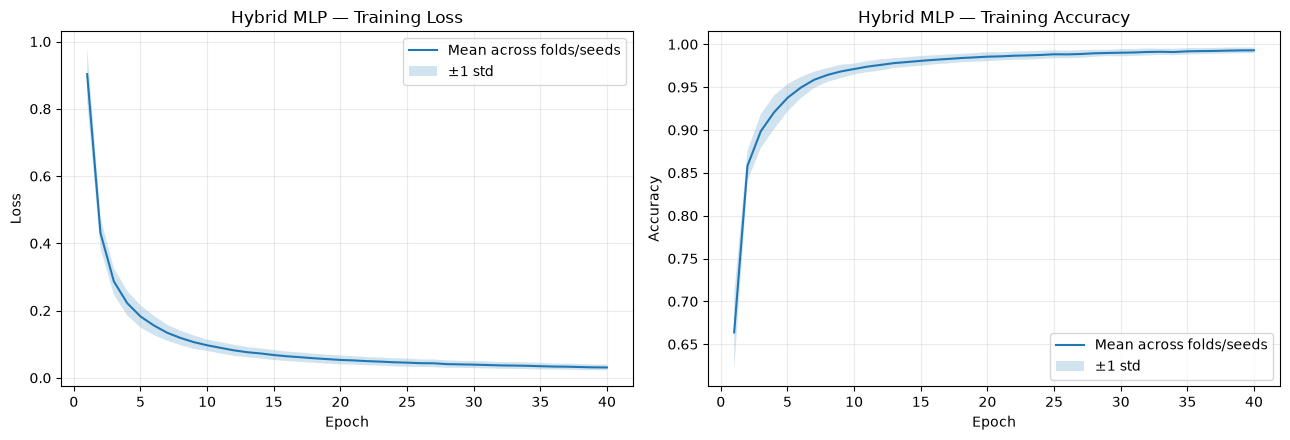

In [7]:
epochs = np.arange(1, EPOCHS + 1)
loss_curves = np.stack([h['loss'] for h in history_log])
accuracy_curves = np.stack([h['accuracy'] for h in history_log])

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, values, title, ylabel in [
    (axes[0], loss_curves, 'Hybrid MLP — Training Loss', 'Loss'),
    (axes[1], accuracy_curves, 'Hybrid MLP — Training Accuracy', 'Accuracy'),
]:
    mean, std = values.mean(axis=0), values.std(axis=0)
    ax.plot(epochs, mean, label='Mean across folds/seeds')
    ax.fill_between(epochs, mean - std, mean + std, alpha=0.2, label='±1 std')
    ax.set(title=title, xlabel='Epoch', ylabel=ylabel)
    ax.grid(alpha=0.25)
    ax.legend()
plt.tight_layout()
plt.show()

## 6. Confusion Matrix tổng hợp 10 seed

Với từng file, lấy trung bình xác suất OOF từ 10 seed rồi chọn `lớp có xác suất cao nhất`. Vì vậy mỗi file đóng góp đúng một lần vào `confusion matrix consensus`; đây là ma trận của dự đoán tổng hợp, không phải trung bình số học của 10 ma trận riêng biệt.

Đã tổng hợp 10 seed; mỗi seed có 40 file OOF.
Confusion Matrix — mean of row-normalized per-seed matrices:


,Normal,IR,OR,B
Normal,1.000,0.000,0.000,0.000
IR,0.000,0.933,0.000,0.067
OR,0.058,0.000,0.858,0.083
B,0.083,0.000,0.000,0.917


Độ lệch chuẩn giữa các seed của từng ô (tham khảo):


,Normal,IR,OR,B
Normal,0.000,0.000,0.00,0.000
IR,0.000,0.035,0.00,0.035
OR,0.040,0.000,0.04,0.000
B,0.079,0.000,0.00,0.079


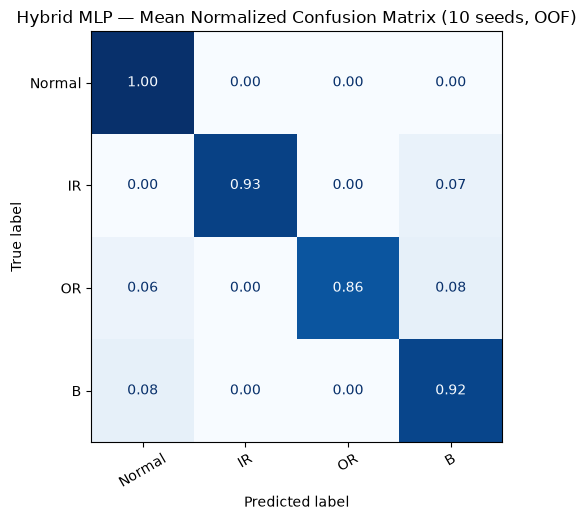

Đã lưu ma trận trung bình: f:\CODE\NCKH_TinyML\TinyML_CWRU\outputs\model_export_hybrid\hybrid_oof_confusion_matrix_mean_10_seeds.csv
Đã lưu độ lệch chuẩn: f:\CODE\NCKH_TinyML\TinyML_CWRU\outputs\model_export_hybrid\hybrid_oof_confusion_matrix_std_10_seeds.csv
Đã lưu confusion matrix từng seed: f:\CODE\NCKH_TinyML\TinyML_CWRU\outputs\model_export_hybrid\hybrid_oof_confusion_matrix_by_seed.csv
Đã lưu hình: f:\CODE\NCKH_TinyML\TinyML_CWRU\outputs\model_export_hybrid\hybrid_oof_confusion_matrix_mean_10_seeds.png


In [8]:
# Tính confusion matrix riêng cho từng seed, sau đó lấy trung bình ma trận đã chuẩn hóa theo hàng.
# Mỗi file phải có đúng một dự đoán OOF trong mỗi seed.
# Nếu kernel vừa khởi động lại, nạp OOF predictions đã lưu để KHÔNG phải huấn luyện lại 40 fold.

if 'predictions_df' not in globals() or predictions_df.empty:
    _oof_path = os.path.join(EXPORT_DIR, 'hybrid_oof_predictions_by_file_seed.csv')
    if not os.path.isfile(_oof_path):
        raise FileNotFoundError(
            f"Không có biến predictions_df và cũng không tìm thấy {_oof_path}. "
            "Hãy chạy cell huấn luyện 10 seed × 4 fold trước, hoặc đặt file OOF predictions "
            "đã lưu vào EXPORT_DIR."
        )
    predictions_df = pd.read_csv(_oof_path)
    print(f'Đã nạp OOF predictions có sẵn: {_oof_path}')

expected_seeds = set(int(s) for s in SEEDS)
observed_seeds = set(predictions_df['seed'].astype(int).unique())
if observed_seeds != expected_seeds:
    raise ValueError(
        f"Danh sách seed không khớp. Mong đợi {sorted(expected_seeds)}, "
        f"nhận {sorted(observed_seeds)}."
    )

n_expected_files = int(feature_df[GROUP_COL].nunique())
if predictions_df.groupby('file_id')['y_true'].nunique().gt(1).any():
    raise ValueError('Nhãn thật y_true của một file không nhất quán giữa các seed.')
if predictions_df.duplicated(subset=['seed', 'file_id']).any():
    duplicated = predictions_df.loc[
        predictions_df.duplicated(subset=['seed', 'file_id'], keep=False),
        ['seed', 'file_id']
    ].head(10)
    raise ValueError(
        "Có file bị dự đoán nhiều hơn một lần trong cùng seed:\n"
        f"{duplicated.to_string(index=False)}"
    )

files_per_seed = predictions_df.groupby('seed')['file_id'].nunique()
if not (files_per_seed == n_expected_files).all():
    raise ValueError(
        f"Mỗi seed phải có {n_expected_files} file OOF; thực tế: "
        f"{files_per_seed.to_dict()}"
    )

cm_normalized_by_seed = []
cm_count_by_seed = {}
seed_cm_long_rows = []
for seed in SEEDS:
    seed_df = predictions_df.loc[predictions_df['seed'].astype(int) == int(seed)].copy()
    # Đảm bảo nhãn thật của từng file không đổi giữa các seed.
    cm_counts = confusion_matrix(
        seed_df['y_true'].astype(str),
        seed_df['y_pred'].astype(str),
        labels=CLASS_NAMES,
    )
    row_support = cm_counts.sum(axis=1, keepdims=True)
    if np.any(row_support == 0):
        missing = [CLASS_NAMES[i] for i, n in enumerate(row_support.ravel()) if n == 0]
        raise ValueError(f"Seed {seed} không có file test thuộc các lớp: {missing}")

    cm_norm = cm_counts.astype(float) / row_support
    cm_count_by_seed[int(seed)] = cm_counts
    cm_normalized_by_seed.append(cm_norm)

    for i, true_label in enumerate(CLASS_NAMES):
        for j, pred_label in enumerate(CLASS_NAMES):
            seed_cm_long_rows.append({
                'seed': int(seed),
                'true_label': true_label,
                'predicted_label': pred_label,
                'count': int(cm_counts[i, j]),
                'row_normalized_rate': float(cm_norm[i, j]),
                'n_true_files_for_class': int(row_support[i, 0]),
            })

cm_stack = np.stack(cm_normalized_by_seed, axis=0)  # (n_seeds, n_classes, n_classes)
cm_mean = cm_stack.mean(axis=0)
cm_std = cm_stack.std(axis=0, ddof=1)  # mức dao động giữa các seed, không phải CI

cm_mean_df = pd.DataFrame(cm_mean, index=CLASS_NAMES, columns=CLASS_NAMES)
cm_std_df = pd.DataFrame(cm_std, index=CLASS_NAMES, columns=CLASS_NAMES)

print(f"Đã tổng hợp {len(SEEDS)} seed; mỗi seed có {n_expected_files} file OOF.")
print("Confusion Matrix — mean of row-normalized per-seed matrices:")
display(cm_mean_df.round(3))
print("Độ lệch chuẩn giữa các seed của từng ô (tham khảo):")
display(cm_std_df.round(3))

fig, ax = plt.subplots(figsize=(6.5, 5.3))
ConfusionMatrixDisplay(cm_mean, display_labels=CLASS_NAMES).plot(
    ax=ax, values_format='.2f', cmap='Blues', colorbar=False
)
ax.set_title('Hybrid MLP — Mean Normalized Confusion Matrix (10 seeds, OOF)')
ax.set_xlabel('Predicted label')
ax.set_ylabel('True label')
ax.tick_params(axis='x', rotation=30)
plt.tight_layout()

# Lưu ma trận trung bình, độ lệch chuẩn và dữ liệu per-seed để có thể kiểm tra lại.
os.makedirs(EXPORT_DIR, exist_ok=True)
cm_mean_path = os.path.join(EXPORT_DIR, 'hybrid_oof_confusion_matrix_mean_10_seeds.csv')
cm_std_path = os.path.join(EXPORT_DIR, 'hybrid_oof_confusion_matrix_std_10_seeds.csv')
cm_by_seed_path = os.path.join(EXPORT_DIR, 'hybrid_oof_confusion_matrix_by_seed.csv')
cm_plot_path = os.path.join(EXPORT_DIR, 'hybrid_oof_confusion_matrix_mean_10_seeds.png')
cm_mean_df.to_csv(cm_mean_path, encoding='utf-8-sig', index_label='true_label')
cm_std_df.to_csv(cm_std_path, encoding='utf-8-sig', index_label='true_label')
pd.DataFrame(seed_cm_long_rows).to_csv(cm_by_seed_path, index=False, encoding='utf-8-sig')
fig.savefig(cm_plot_path, dpi=200, bbox_inches='tight')
plt.show()

print('Đã lưu ma trận trung bình:', cm_mean_path)
print('Đã lưu độ lệch chuẩn:', cm_std_path)
print('Đã lưu confusion matrix từng seed:', cm_by_seed_path)
print('Đã lưu hình:', cm_plot_path)


In [9]:
from pathlib import Path

out_dir = Path(EXPORT_DIR)
out_dir.mkdir(parents=True, exist_ok=True)

out_path = out_dir / "hybrid_oof_predictions_by_file_seed.csv"

predictions_df.to_csv(
    out_path,
    index=False,
    encoding="utf-8-sig",
)

print(f"Đã lưu: {out_path}")
print(f"Số dòng: {len(predictions_df)}")
print("Các cột:", predictions_df.columns.tolist())

Đã lưu: f:\CODE\NCKH_TinyML\TinyML_CWRU\outputs\model_export_hybrid\hybrid_oof_predictions_by_file_seed.csv
Số dòng: 400
Các cột: ['variant', 'seed', 'fold', 'file_id', 'y_true', 'y_pred', 'p_0', 'p_1', 'p_2', 'p_3']


## 7. Ablation Study — loại bỏ từng nhóm đặc trưng

So sánh đủ 28 đặc trưng với ba biến thể: bỏ `time_` (miền thời gian), bỏ `order_` (phổ/order) hoặc bỏ `envelope_` (phổ đường bao). Các biến thể dùng **cùng 10 seed và cùng fold** như baseline. Đây là 120 lượt huấn luyện bổ sung (3 biến thể × 40 fold/seed).

In [10]:
feature_groups = {
    'Time-domain': [c for c in FEATURE_COLS if c.startswith('time_')],
    'Order/frequency': [c for c in FEATURE_COLS if c.startswith('order_')],
    'Envelope': [c for c in FEATURE_COLS if c.startswith('envelope_')],
}
print('Số đặc trưng mỗi nhóm:', {name: len(cols) for name, cols in feature_groups.items()})

ablation_parts = [predictions_df.copy()]
for group_name, group_cols in feature_groups.items():
    reduced_cols = [c for c in FEATURE_COLS if c not in group_cols]
    variant_name = f'Without {group_name}'
    print(f'\n{variant_name}: {len(reduced_cols)} đặc trưng')
    reduced_predictions, _ = run_group_cv(
        reduced_cols, variant=variant_name, collect_history=False
    )
    ablation_parts.append(reduced_predictions)

ablation_predictions = pd.concat(ablation_parts, ignore_index=True)
ablation_by_seed = calculate_seed_metrics(ablation_predictions, condition_col='variant')

ablation_summary = (ablation_by_seed.groupby('variant')
    .agg(accuracy_mean=('Accuracy', 'mean'), accuracy_std=('Accuracy', 'std'),
         macro_f1_mean=('Macro-F1', 'mean'), macro_f1_std=('Macro-F1', 'std'))
    .reset_index())
base = ablation_summary.loc[ablation_summary['variant'] == 'All 28 features'].iloc[0]
ablation_summary['Accuracy drop (pp)'] = (
    base['accuracy_mean'] - ablation_summary['accuracy_mean']
) * 100
ablation_summary['Macro-F1 drop (pp)'] = (
    base['macro_f1_mean'] - ablation_summary['macro_f1_mean']
) * 100
ablation_summary = ablation_summary.set_index('variant').loc[
    ['All 28 features', 'Without Time-domain', 'Without Order/frequency', 'Without Envelope']
].reset_index()
display(ablation_summary.
        
        round(4))

Số đặc trưng mỗi nhóm: {'Time-domain': 11, 'Order/frequency': 10, 'Envelope': 7}

Without Time-domain: 17 đặc trưng
Without Time-domain: hoàn thành seed 42
Without Time-domain: hoàn thành seed 43
Without Time-domain: hoàn thành seed 44
Without Time-domain: hoàn thành seed 45
Without Time-domain: hoàn thành seed 46
Without Time-domain: hoàn thành seed 47
Without Time-domain: hoàn thành seed 48
Without Time-domain: hoàn thành seed 49
Without Time-domain: hoàn thành seed 50
Without Time-domain: hoàn thành seed 51

Without Order/frequency: 18 đặc trưng
Without Order/frequency: hoàn thành seed 42
Without Order/frequency: hoàn thành seed 43
Without Order/frequency: hoàn thành seed 44
Without Order/frequency: hoàn thành seed 45
Without Order/frequency: hoàn thành seed 46
Without Order/frequency: hoàn thành seed 47
Without Order/frequency: hoàn thành seed 48
Without Order/frequency: hoàn thành seed 49
Without Order/frequency: hoàn thành seed 50
Without Order/frequency: hoàn thành seed 51

With

,variant,accuracy_mean,accuracy_std,macro_f1_mean,macro_f1_std,Accuracy drop (pp),Macro-F1 drop (pp)
0,All 28 features,0.9125,0.0317,0.9030,0.0417,0.0,0.0000
1,Without Time-domain,0.9625,0.0177,0.9540,0.0268,-5.0,-5.1039
2,Without Order/frequency,0.9025,0.0322,0.9124,0.0283,1.0,-0.9365
3,Without Envelope,0.8925,0.0265,0.8848,0.0275,2.0,1.8198


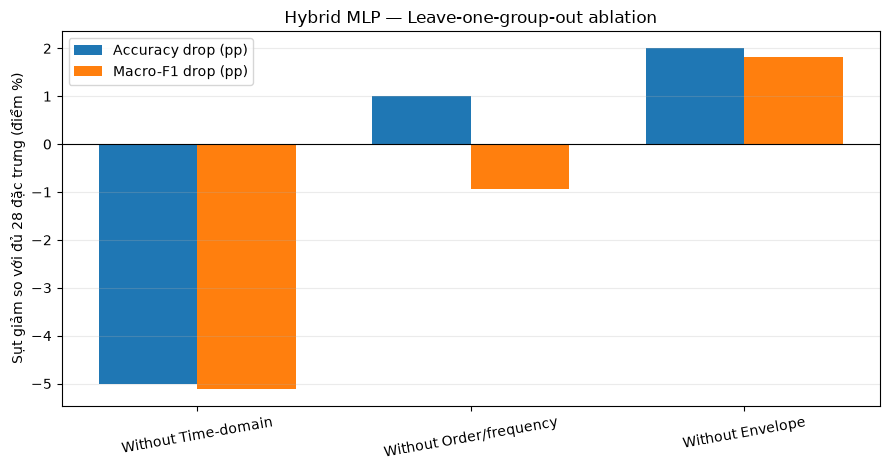

In [11]:
plot_df = ablation_summary[ablation_summary['variant'] != 'All 28 features'].copy()
x = np.arange(len(plot_df))
width = 0.36
fig, ax = plt.subplots(figsize=(9, 4.8))
ax.bar(x - width / 2, plot_df['Accuracy drop (pp)'], width, label='Accuracy drop (pp)')
ax.bar(x + width / 2, plot_df['Macro-F1 drop (pp)'], width, label='Macro-F1 drop (pp)')
ax.axhline(0, color='black', linewidth=0.8)
ax.set_xticks(x, plot_df['variant'], rotation=10)
ax.set_ylabel('Sụt giảm so với đủ 28 đặc trưng (điểm %)')
ax.set_title('Hybrid MLP — Leave-one-group-out ablation')
ax.grid(axis='y', alpha=0.25)
ax.legend()
plt.tight_layout()
plt.show()

## 8. Xuất mô hình Edge AI — H5 và TFLite INT8

Mô hình triển khai được huấn luyện lại trên toàn bộ bảng Hybrid với số epoch cố định. Thống kê Z-score tính trên toàn bộ dữ liệu dùng để huấn luyện mô hình triển khai và được gộp đại số vào Dense đầu tiên; vì vậy mô hình xuất nhận trực tiếp 28 đặc trưng ở thang đo gốc theo đúng `feature_columns` trong metadata.

Đây là mô hình cuối cho triển khai, **không** dùng kết quả fit trên toàn bảng làm Accuracy/Macro-F1 đánh giá tổng quát hóa. Hiệu năng báo cáo vẫn lấy từ Group K-Fold ở các mục trước.

In [12]:
os.makedirs(EXPORT_DIR, exist_ok=True)
X_all = feature_df[FEATURE_COLS].to_numpy(dtype=np.float32)
y_all = feature_df[LABEL_COL].map(CLASS_TO_ID).to_numpy(dtype=np.int32)

norm_mean = X_all.mean(axis=0).astype(np.float32)
raw_variance = X_all.var(axis=0)
# Tương đương StandardScaler: đặc trưng variance gần 0 dùng scale=1.
norm_variance = np.where(raw_variance < 1e-12, 1.0, raw_variance).astype(np.float32)

tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(42)
final_model = models.build_primary_mlp(
    input_dim=len(FEATURE_COLS),
    n_classes=len(CLASS_NAMES),
    norm_mean=norm_mean,
    norm_variance=norm_variance,
    name='mlp_4class_hybrid_deploy_normalized',
)
final_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy'],
)
final_model.fit(X_all, y_all, epochs=EPOCHS, batch_size=BATCH_SIZE, verbose=0)

# Gộp z-score vào Dense đầu tiên để giảm phụ thuộc vào lớp Normalization khi deploy.
deployment_model = models.build_primary_mlp(
    input_dim=len(FEATURE_COLS), n_classes=len(CLASS_NAMES),
    name='mlp_4class_hybrid_deploy',
)
first_kernel, first_bias = final_model.get_layer('dense_32_0').get_weights()
feature_scale = np.sqrt(norm_variance)
fused_kernel = first_kernel / feature_scale[:, None]
fused_bias = first_bias - (norm_mean / feature_scale) @ first_kernel
deployment_model.get_layer('dense_32_0').set_weights([fused_kernel, fused_bias])
for layer_name in ['dense_16_1', 'output']:
    deployment_model.get_layer(layer_name).set_weights(final_model.get_layer(layer_name).get_weights())
deployment_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE),
    loss='sparse_categorical_crossentropy', metrics=['accuracy'],
)

# So sánh xác suất trước/sau gộp chuẩn hóa.
n_compare = min(256, len(X_all))
prob_original = final_model.predict(X_all[:n_compare], verbose=0)
prob_fused = deployment_model.predict(X_all[:n_compare], verbose=0)
fusion_error = float(np.max(np.abs(prob_original - prob_fused)))
print(f'Max probability difference after fusing Z-score: {fusion_error:.3e}')

h5_path = os.path.join(EXPORT_DIR, 'mlp_4class_hybrid.h5')
tflite_path = os.path.join(EXPORT_DIR, 'mlp_4class_hybrid_int8.tflite')
metadata_path = os.path.join(EXPORT_DIR, 'mlp_4class_hybrid_metadata.json')
deployment_model.save(h5_path, include_optimizer=False)

# Representative samples dùng thang đo đặc trưng gốc vì Z-score đã được gộp vào Dense.
rng = np.random.default_rng(42)
rep_idx = rng.choice(len(X_all), size=min(200, len(X_all)), replace=False)
representative_samples = X_all[rep_idx]
def representative_dataset():
    for sample in representative_samples:
        yield [sample.reshape(1, -1).astype(np.float32)]

converter = tf.lite.TFLiteConverter.from_keras_model(deployment_model)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
converter.representative_dataset = representative_dataset
converter.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
converter.inference_input_type = tf.int8
converter.inference_output_type = tf.int8
tflite_bytes = converter.convert()
with open(tflite_path, 'wb') as f:
    f.write(tflite_bytes)

# Smoke test INT8 và đo tỷ lệ khớp top-1 với Keras.
interpreter = tf.lite.Interpreter(model_content=tflite_bytes)
interpreter.allocate_tensors()
input_detail = interpreter.get_input_details()[0]
output_detail = interpreter.get_output_details()[0]
in_scale, in_zero = input_detail['quantization']
out_scale, out_zero = output_detail['quantization']
if in_scale <= 0 or out_scale <= 0:
    raise ValueError('TFLite input/output quantization scale không hợp lệ.')

n_parity = min(256, len(X_all))
keras_pred = np.argmax(deployment_model.predict(X_all[:n_parity], verbose=0), axis=1)
tflite_pred = []
for sample in X_all[:n_parity]:
    q_input = np.clip(np.rint(sample / in_scale + in_zero), -128, 127).astype(np.int8)
    interpreter.set_tensor(input_detail['index'], q_input.reshape(1, -1))
    interpreter.invoke()
    q_output = interpreter.get_tensor(output_detail['index']).astype(np.float32)
    output_float = (q_output - out_zero) * out_scale
    tflite_pred.append(int(np.argmax(output_float[0])))
quantized_agreement = float(np.mean(keras_pred == np.asarray(tflite_pred)))

metadata = {
    'model': 'MLP Hybrid 4-class',
    'classes_in_output_order': CLASS_NAMES,
    'feature_columns_in_input_order': FEATURE_COLS,
    'input_shape': [1, len(FEATURE_COLS)],
    'input_contract': 'Feed unstandardized 28 Hybrid features in feature_columns_in_input_order.',
    'normalization': 'Z-score stats from all feature rows used to train final deployment model; algebraically fused into first Dense weights/bias.',
    'normalization_fusion_max_abs_probability_error': fusion_error,
    'keras_vs_tflite_int8_top1_agreement_on_training_sample': quantized_agreement,
    'keras_h5_path': os.path.abspath(h5_path),
    'tflite_int8_path': os.path.abspath(tflite_path),
    'tflite_input': {'dtype': str(input_detail['dtype']), 'shape': input_detail['shape'].tolist(),
                     'scale': float(in_scale), 'zero_point': int(in_zero)},
    'tflite_output': {'dtype': str(output_detail['dtype']), 'shape': output_detail['shape'].tolist(),
                      'scale': float(out_scale), 'zero_point': int(out_zero)},
    'cv_accuracy_mean': float(metrics_by_seed['Accuracy'].mean()),
    'cv_accuracy_std': float(metrics_by_seed['Accuracy'].std(ddof=1)),
    'cv_macro_f1_mean': float(metrics_by_seed['Macro-F1'].mean()),
    'cv_macro_f1_std': float(metrics_by_seed['Macro-F1'].std(ddof=1)),
    'tflite_builtin_int8_only': True,
}
with open(metadata_path, 'w', encoding='utf-8') as f:
    json.dump(metadata, f, ensure_ascii=False, indent=2)

print('Đã xuất mô hình Hybrid:')
print('H5:       ', os.path.abspath(h5_path))
print('TFLite INT8:', os.path.abspath(tflite_path))
print('Metadata: ', os.path.abspath(metadata_path))
print(f'Keras ↔ TFLite INT8 top-1 agreement trên {n_parity} mẫu: {quantized_agreement:.3f}')

Max probability difference after fusing Z-score: 8.643e-07


f:\CODE\NCKH_TinyML\TinyML_CWRU\.venv\Lib\site-packages\keras\src\engine\training.py:3103: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


INFO:tensorflow:Assets written to: C:\Users\Admin\AppData\Local\Temp\tmpqds03nrk\assets


INFO:tensorflow:Assets written to: C:\Users\Admin\AppData\Local\Temp\tmpqds03nrk\assets


Đã xuất mô hình Hybrid:
H5:        f:\CODE\NCKH_TinyML\TinyML_CWRU\outputs\model_export_hybrid\mlp_4class_hybrid.h5
TFLite INT8: f:\CODE\NCKH_TinyML\TinyML_CWRU\outputs\model_export_hybrid\mlp_4class_hybrid_int8.tflite
Metadata:  f:\CODE\NCKH_TinyML\TinyML_CWRU\outputs\model_export_hybrid\mlp_4class_hybrid_metadata.json
Keras ↔ TFLite INT8 top-1 agreement trên 256 mẫu: 1.000


f:\CODE\NCKH_TinyML\TinyML_CWRU\.venv\Lib\site-packages\tensorflow\lite\python\convert.py:953: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(


## 9. Lưu ý triển khai STM32Cube.AI

- Firmware phải tạo đúng 28 đặc trưng Hybrid, cùng thứ tự cột ghi trong `mlp_4class_hybrid_metadata.json`.
- `.h5` và `.tflite` đã gộp phép chuẩn hóa vào Dense đầu tiên; input của chúng là đặc trưng **chưa Z-score**.
- Firmware TFLite INT8 phải dùng đúng `input_scale` và `input_zero_point` để lượng tử hóa input; đầu ra được giải lượng tử hóa theo metadata.
- Giới hạn converter ở `TFLITE_BUILTINS_INT8` tránh custom ops, nhưng vẫn cần import/compile bằng phiên bản STM32Cube.AI đang dùng và đo Flash/RAM/latency trên board thật.
- Thỏa thuận đo lường: Accuracy/Macro-F1 báo cáo ở trên lấy từ dự đoán ngoài mẫu theo file; không dùng độ chính xác train của mô hình export làm kết quả nghiên cứu.